In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [47]:
data = pd.read_csv("C2--Trace--00916.csv", header=4)


In [48]:
data

,Time,Ampl
0,-2.500750e-07,0.003468
1,-2.499750e-07,0.005923
2,-2.498750e-07,0.005368
3,-2.497750e-07,0.002233
4,-2.496750e-07,0.002053
...,...,...
4997,2.496250e-07,0.007463
4998,2.497250e-07,0.008531
4999,2.498250e-07,0.013095
5000,2.499250e-07,0.016729


In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5002 entries, 0 to 5001
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    5002 non-null   float64
 1   Ampl    5002 non-null   float64
dtypes: float64(2)
memory usage: 78.3 KB


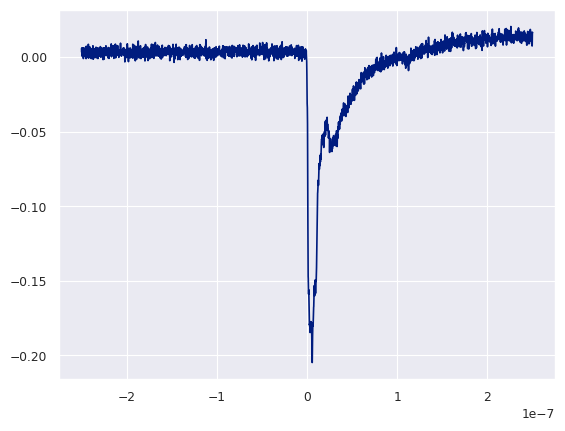

In [50]:
plt.figure()
plt.plot(data["Time"], data["Ampl"])
plt.show()
#

In [51]:
data_p = data[(data["Time"]>= -0.02e-7) & (data["Time"]<= 0.5e-7)]

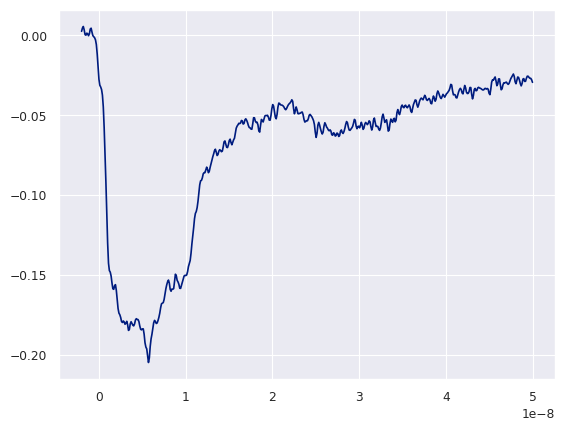

In [52]:
plt.plot(data_p["Time"], data_p["Ampl"])
plt.show()

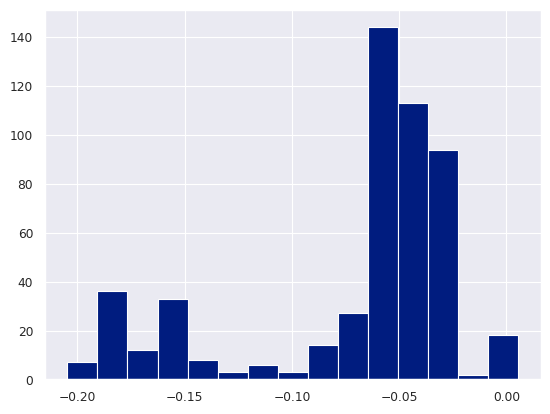

In [53]:
plt.hist(data_p["Ampl"], bins=15)
plt.show()

In [54]:
data_a = data[(data["Time"]<= -0.02e-7)]

ruido = data_a

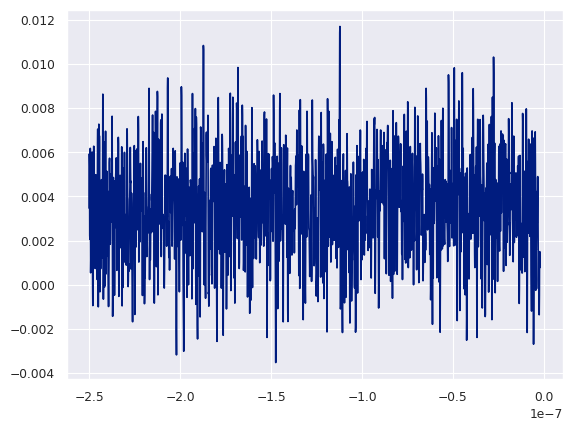

In [55]:
plt.plot(ruido["Time"], ruido["Ampl"])
plt.show()

In [56]:
ruido.describe()

,Time,Ampl
count,2.481000e+03,2481.000000
mean,-1.260750e-07,0.003502
std,7.163474e-08,0.002227
min,-2.500750e-07,-0.003523
25%,-1.880750e-07,0.002011
50%,-1.260750e-07,0.003565
75%,-6.407499e-08,0.005022
max,-2.074990e-09,0.011694


In [57]:


# Amplitudes de ruido
amplitud = ruido["Ampl"].dropna()

# Medidas de tendencia central
media = amplitud.mean()
mediana = amplitud.median()

# Medidas de dispersión
sigma = amplitud.std()  # Desviación estándar muestral
q1 = amplitud.quantile(0.25)
q3 = amplitud.quantile(0.75)




In [58]:
from scipy.stats import norm

N = len(ruido["Ampl"])
ancho_bin = (ruido["Ampl"].max() - ruido["Ampl"].min()) / 20

# Valores de x para dibujar una curva suave
x_gauss = np.linspace(
    ruido["Ampl"].min(),
    ruido["Ampl"].max(),
    1000
)

# Distribución normal con la media y desviación estándar del ruido
gauss = norm.pdf(x_gauss, loc=media, scale=sigma)

gauss_e = gauss * N * ancho_bin

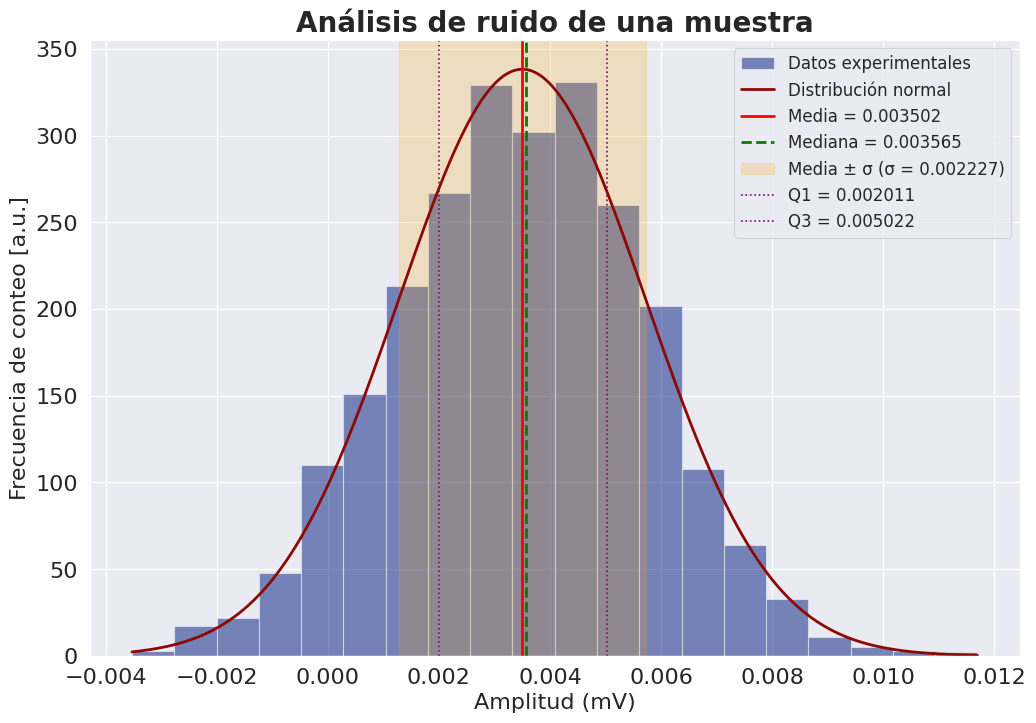

In [59]:
sns.set_theme("paper", palette='dark')

plt.figure(figsize=(12,8))

# Histograma de los datos
plt.hist(ruido["Ampl"], density=False, bins=20, label="Datos experimentales",alpha=0.5, hatch='')

# Gaussiana
plt.plot(
    x_gauss,
    gauss_e,
    "r-",
    linewidth=2,
    label="Distribución normal"
)


plt.axvline(media, color="red", linestyle="-",
            linewidth=2, label=f"Media = {media:.4g}")

plt.axvline(mediana, color="green", linestyle="--",
            linewidth=2, label=f"Mediana = {mediana:.4g}")

plt.axvspan(media - sigma, media + sigma,
            color="orange", alpha=0.2,
            label=f"Media ± σ (σ = {sigma:.4g})")

plt.axvline(q1, color="purple", linestyle=":",
            label=f"Q1 = {q1:.4g}")

plt.axvline(q3, color="purple", linestyle=":",
            label=f"Q3 = {q3:.4g}")

plt.legend(fontsize=12)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title("Análisis de ruido de una muestra", fontsize=20,
    fontweight="bold")
plt.ylabel('Frecuencia de conteo [a.u.]', fontsize=16)
plt.xlabel('Amplitud (mV)', fontsize=16)
plt.show()

In [60]:
import zipfile
with zipfile.ZipFile("datos.zip", "r") as zip_ref:
    zip_ref.extractall("datos")

In [61]:
import glob
import os

archivos = glob.glob("datos/**/*.csv", recursive=True)

print("Total de archivos CSV:", len(archivos))

Total de archivos CSV: 926


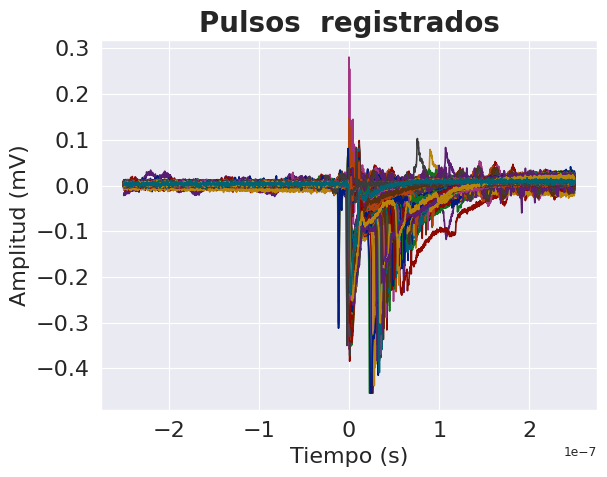

In [62]:
for archivo in archivos[:900]:
    Data = pd.read_csv(archivo, header=4)
    plt.plot(Data["Time"], Data["Ampl"])

#plt.legend(fontsize=12)
plt.grid(True)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title("Pulsos  registrados", fontsize=20,
    fontweight="bold")
plt.ylabel('Amplitud (mV)', fontsize=16)
plt.xlabel('Tiempo (s)', fontsize=16)
plt.show()

In [63]:
archivos_validos=[]

In [64]:
for archivo in archivos[:900]:
    Data = pd.read_csv(archivo, header=4)
    if not (Data["Ampl"] > 0.5).any():
      archivos_validos.append(archivo)

print("Archivos totales:", len(archivos))
print("Archivos descartados:", len(archivos) - len(archivos_validos))
print("Archivos válidos:", len(archivos_validos))

Archivos totales: 926
Archivos descartados: 26
Archivos válidos: 900


Número de archivos: 926
Longitudes distintas: {5002}


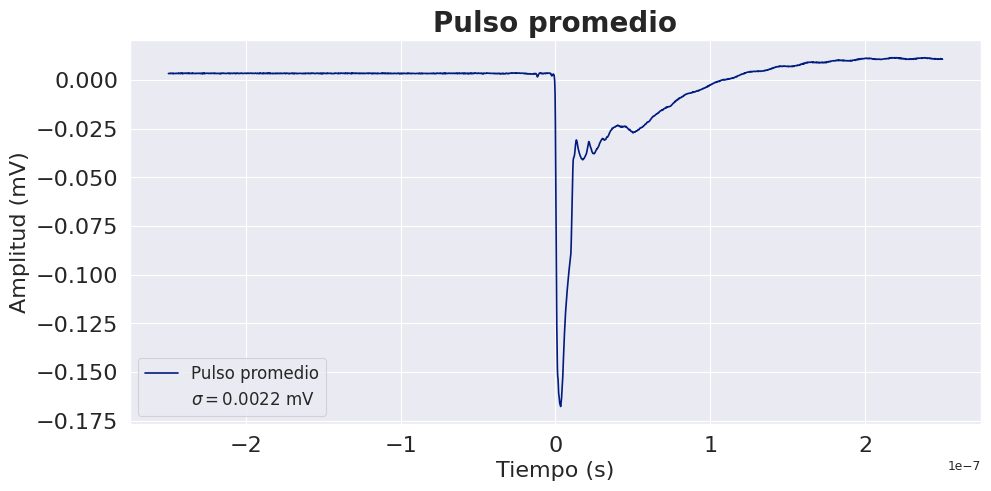

In [65]:

amplitudes = []
tiempos = []

for archivo in archivos:
    Data = pd.read_csv(archivo, header=4)

    amplitudes.append(
        pd.to_numeric(Data["Ampl"], errors="coerce").to_numpy()
    )
    tiempos.append(
        pd.to_numeric(Data["Time"], errors="coerce").to_numpy()
    )

# Comprobar las longitudes
longitudes = [len(a) for a in amplitudes]
print("Número de archivos:", len(amplitudes))
print("Longitudes distintas:", set(longitudes))

# Promediar solo si todas tienen la misma longitud
if len(set(longitudes)) == 1:
    amplitud_promedio = np.mean(
        np.vstack(amplitudes), axis=0
    )

    plt.figure(figsize=(10, 5))
    plt.plot(tiempos[0], amplitud_promedio,
             label="Pulso promedio")
    plt.plot([], [], " ", label=fr"$\sigma = {sigma:.4f}\ \mathrm{{mV}}$")
    plt.title("Pulso promedio", fontsize=20,
              fontweight="bold")
    plt.xlabel("Tiempo (s)", fontsize=16)
    plt.ylabel("Amplitud (mV)", fontsize=16)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.grid(True)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("No se pueden promediar punto por punto: "
          "las señales tienen longitudes diferentes.")

In [66]:
# Seleccionar únicamente las regiones de ruido
mascara_ruido = (
    (tiempos[0] <= -0.25e-7))

tiempos_ruido = tiempos[0][mascara_ruido]
amplitud_ruido = amplitud_promedio[mascara_ruido]

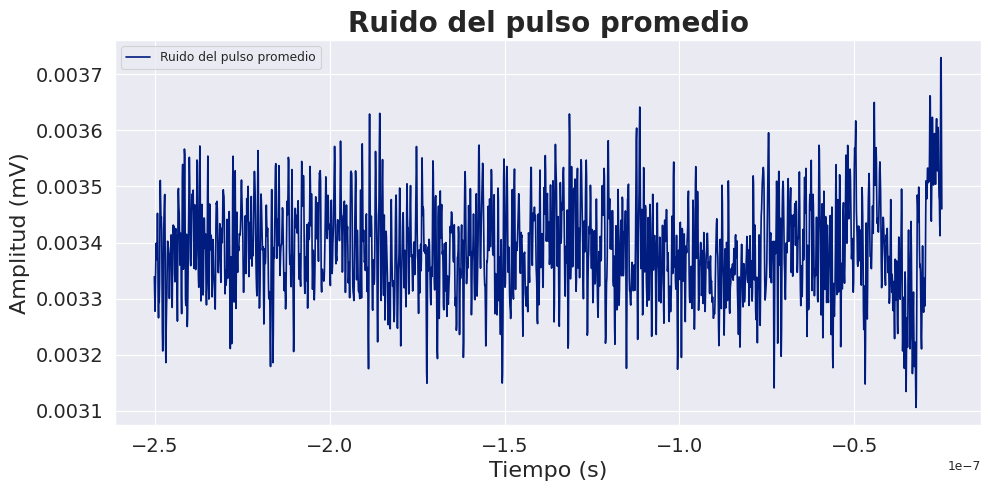

In [67]:
plt.figure(figsize=(10, 5))

plt.plot(tiempos_ruido, amplitud_ruido,
         label="Ruido del pulso promedio")

plt.xlabel("Tiempo (s)", fontsize=16)
plt.ylabel("Amplitud (mV)", fontsize=16)
plt.title("Ruido del pulso promedio", fontsize=20,
          fontweight="bold")

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [68]:
# Amplitudes de ruido
amplitud2 = np.asarray(amplitud_ruido)

# Medidas de tendencia central
media2 = np.mean(amplitud2)
mediana2 = np.median(amplitud2)

# Medidas de dispersión
sigma2 = np.std(amplitud2, ddof=1)  # Desviación estándar muestral
q12 = np.percentile(amplitud2, 25)
q32 = np.percentile(amplitud2, 75)

# Mostrar resultados
print(f"Media: {media2:.6g}")
print(f"Mediana: {mediana2:.6g}")
print(f"Desviación estándar: {sigma2:.6g}")
print(f"Primer cuartil (Q1): {q12:.6g}")
print(f"Tercer cuartil (Q3): {q32:.6g}")
print(f"Rango intercuartílico: {q32 - q12:.6g}")


Media: 0.0033896
Mediana: 0.00338586
Desviación estándar: 8.54104e-05
Primer cuartil (Q1): 0.00333126
Tercer cuartil (Q3): 0.00344657
Rango intercuartílico: 0.000115317


In [69]:
M = len(amplitud_ruido)
ancho_bin2 = (amplitud_ruido.max() - amplitud_ruido.min()) / 20

# Valores de x para dibujar una curva suave
a_gauss = np.linspace(
    amplitud_ruido.min(),
    amplitud_ruido.max(),
    1000
)

# Distribución normal con la media y desviación estándar del ruido
gauss2 = norm.pdf(a_gauss, loc=media2, scale=sigma2)

gauss_f = gauss2 * M * ancho_bin2

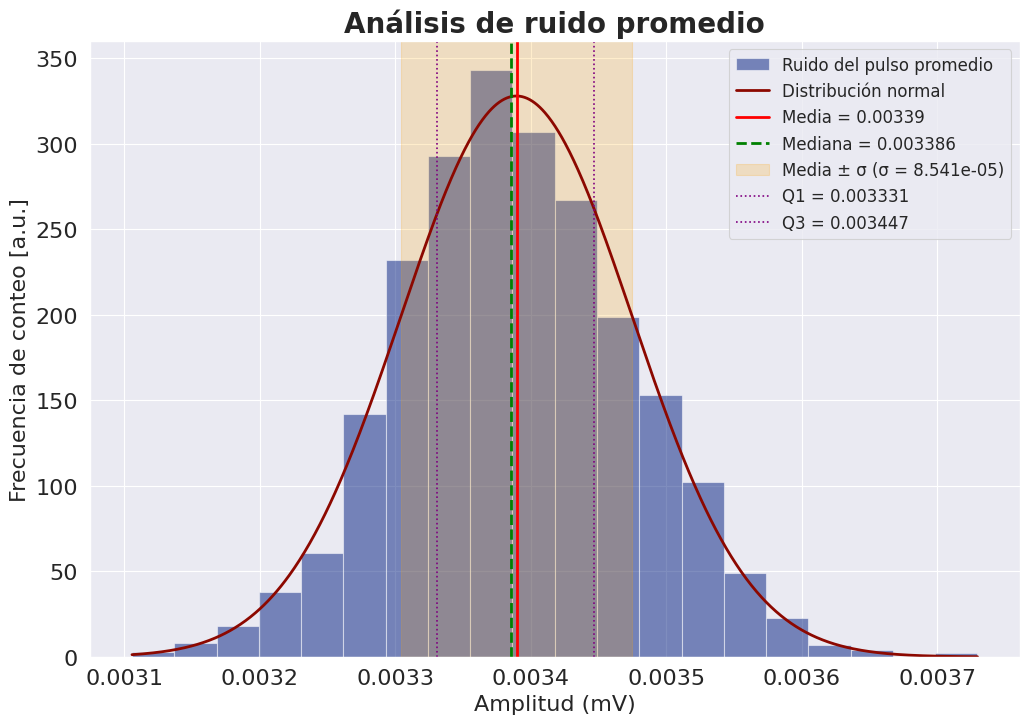

In [70]:
plt.figure(figsize=(12,8))

# Histograma de los datos
plt.hist(amplitud_ruido,
         label="Ruido del pulso promedio", density=False, bins=20, alpha=0.5, hatch='')

# Gaussiana
plt.plot(
    a_gauss,
    gauss_f,
    "r-",
    linewidth=2,
    label="Distribución normal"
)


plt.axvline(media2, color="red", linestyle="-",
            linewidth=2, label=f"Media = {media2:.4g}")

plt.axvline(mediana2, color="green", linestyle="--",
            linewidth=2, label=f"Mediana = {mediana2:.4g}")

plt.axvspan(media2 - sigma2, media2 + sigma2,
            color="orange", alpha=0.2,
            label=f"Media ± σ (σ = {sigma2:.4g})")

plt.axvline(q12, color="purple", linestyle=":",
            label=f"Q1 = {q12:.4g}")

plt.axvline(q32, color="purple", linestyle=":",
            label=f"Q3 = {q32:.4g}")

plt.legend(fontsize=12)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title("Análisis de ruido promedio", fontsize=20,
    fontweight="bold")
plt.ylabel('Frecuencia de conteo [a.u.]', fontsize=16)
plt.xlabel('Amplitud (mV)', fontsize=16)
plt.show()